<a href="https://colab.research.google.com/github/greeshmareddy98/MLA0201-FOML/blob/main/EXP_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training Data:
      Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High  Strong  Cool   Change        Yes

Specific Boundary S: ['Sunny', 'Warm', '?', 'Strong', '?', '?']

General Boundary G:
['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']


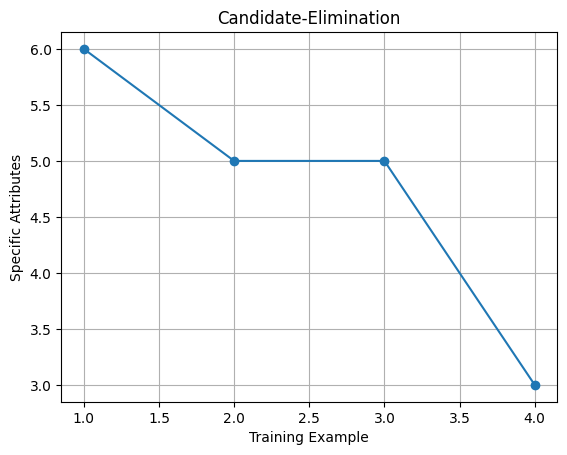

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong'] * 4,
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)
print("Training Data:\n", df)

A = list(df.columns[:-1])
S = ['0'] * len(A)
G = [['?'] * len(A)]
history = []

for _, r in df.iterrows():
    if r.EnjoySport == 'Yes':
        for i in range(len(A)):
            if S[i] == '0':
                S[i] = r[A[i]]
            elif S[i] != r[A[i]]:
                S[i] = '?'
    else:
        G = [[S[i] if g[i] == '?' and S[i] != '?' else g[i]
              for i in range(len(A))] for g in G]
    history.append(sum(x not in ['0', '?'] for x in S))

print("\nSpecific Boundary S:", S)
print("\nGeneral Boundary G:")
for g in G:
    print(g)

plt.plot(range(1, 5), history, marker='o')
plt.xlabel("Training Example")
plt.ylabel("Specific Attributes")
plt.title("Candidate-Elimination")
plt.grid()
plt.show()